# Lab 04-05 · Current, Resistance and Conduction

Companion to chapter [04-05](../../chapters/04-05-current-resistance-and-conduction.md). Handout: [README.md](README.md). The ngspice netlist [wire_rc.cir](wire_rc.cir) simulates the 1 mm wire of Example 04-05.6; run it with `python tools/run_spice.py 04-05` from the repository root.

Cells marked **🔮 Predict** ask for a prediction *before* running. Random numbers use seed 2026.

In [1]:
import math, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.linalg import expm
from scipy.optimize import brentq
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass
e, me = 1.602176634e-19, 9.1093837139e-31
rho_cu, alpha_cu = 1.68e-8, 0.00393
rng = np.random.default_rng(2026)

## Part 1 — A Drude gas in a computer

Simulate many electrons in one dimension. Between collisions each accelerates at $-eE/m$; collisions occur at random (a Poisson process with mean time τ) and reset its velocity to a random thermal value with zero mean. Measure the average velocity.

**🔮 Predict:** if τ doubles, what happens to the drift velocity?

In [2]:
def drude_drift(tau, E, n_el=50000, t_end=None, dt=None, v_th=2.0e3):
    t_end = t_end or 200 * tau
    dt = dt or tau / 50
    v = rng.normal(0, v_th, n_el)
    a = -e * E / me
    vs = []
    for _ in range(int(t_end / dt)):
        v += a * dt
        hit = rng.random(n_el) < dt / tau          # collision probability in this step
        v[hit] = rng.normal(0, v_th, hit.sum())
        vs.append(v.mean())
    return np.mean(vs[len(vs) // 2:])              # average over the steady half
E = 1e4                                            # V/m
for tau in (25e-15, 50e-15):
    vd = drude_drift(tau, E)
    print(f"tau = {tau*1e15:.0f} fs: simulated drift {vd:8.1f} m/s, Drude -e tau E/m = {-e*tau*E/me:8.1f} m/s")

tau = 25 fs: simulated drift    -41.8 m/s, Drude -e tau E/m =    -44.0 m/s


tau = 50 fs: simulated drift    -85.5 m/s, Drude -e tau E/m =    -87.9 m/s


The simulated drift matches $-e\tau E/m$ to within a few percent (the finite time step biases it about 2% low, and the rest is statistical noise), and doubles when τ doubles: mobility is proportional to the mean free time. To keep the noise small the random (thermal) speed is set to 2 km/s, far below a real metal's; the drift does not depend on it, because the random velocities average to zero after every collision.

## Part 2 — Resistance by slicing

A 1 oz copper trace (34.06 µm thick) tapers linearly from 1 mm to 0.2 mm over 100 mm. Integrate $dR = \rho\,dx/(tw(x))$ numerically.

**🔮 Predict:** is the true resistance above or below that of a uniform trace at the average width?

In [3]:
t, L, w1, w2 = 34.06e-6, 0.1, 1e-3, 0.2e-3
w = lambda x: w1 + (w2 - w1) * x / L
R_num = quad(lambda x: rho_cu / (t * w(x)), 0, L)[0]
R_avg = rho_cu * L / (t * (w1 + w2) / 2)
print(f"tapered: {R_num*1e3:.2f} mOhm; uniform at average width: {R_avg*1e3:.2f} mOhm")

tapered: 99.23 mOhm; uniform at average width: 82.21 mOhm


The narrow end dominates because resistance adds as $1/w$: the average-width estimate is 17% low here.

## Part 3 — Self-heating and thermal runaway

A copper conductor with $R$ = 1 Ω at 20 °C carries current $I$ and sheds heat to 25 °C air through a thermal resistance θ = 30 K/W, so $T = 25 + \theta I^2R(T)$ with $R(T) = R_{20}[1 + \alpha(T - 20)]$.

**🔮 Predict:** the steady temperature at 1 A, and whether there is a current above which no steady state exists.

steady temperature at 1 A: 59.68 C
runaway current: 2.912 A


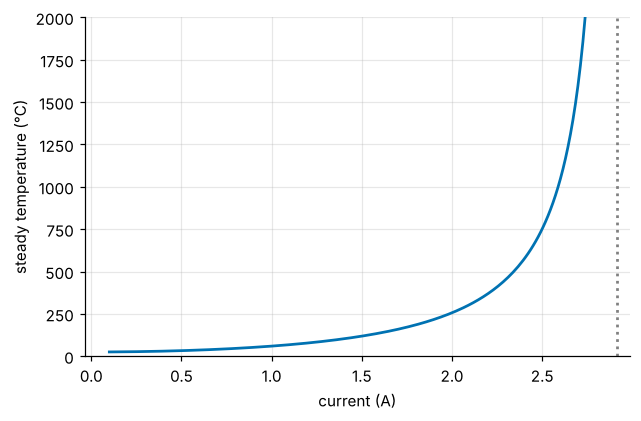

In [4]:
R20, theta, Tamb = 1.0, 30.0, 25.0
def T_steady(I):
    k = theta * I**2 * R20
    if k * alpha_cu >= 1:
        return np.inf                              # heating outruns cooling: runaway
    return (Tamb + k * (1 - alpha_cu * 20)) / (1 - k * alpha_cu)
print(f"steady temperature at 1 A: {T_steady(1.0):.2f} C")
I_crit = 1 / math.sqrt(theta * R20 * alpha_cu)
print(f"runaway current: {I_crit:.3f} A")
I = np.linspace(0.1, 2.85, 200)
plt.plot(I, [T_steady(i) for i in I]); plt.axvline(I_crit, ls=":", color="0.5")
plt.xlabel("current (A)"); plt.ylabel("steady temperature (°C)"); plt.ylim(0, 2000); plt.show()

The fixed point exists only while $\theta I^2R_{20}\alpha < 1$; beyond that, each degree of heating raises the resistance enough to produce more than a degree of extra heating. Real conductors melt or fuse first, which is how a fuse works.

## Part 4 — The distributed RC line

Model a wire as $N$ π-sections and compute the far end's step response exactly (matrix exponential), in units of the total $RC$.

**🔮 Predict:** the 50% delay as a fraction of $RC$.

In [5]:
def t50_ladder(N):
    r = 1.0 / N
    cs = np.full(N, 1.0 / N); cs[-1] = 0.5 / N
    A = np.zeros((N, N))
    for i in range(N):
        A[i, i] -= 1 / (r * cs[i])
        if i > 0: A[i, i - 1] += 1 / (r * cs[i])
        if i < N - 1: A[i, i] -= 1 / (r * cs[i]); A[i, i + 1] += 1 / (r * cs[i])
    b = np.zeros(N); b[0] = 1 / (r * cs[0])
    x_final = -np.linalg.solve(A, b)
    return brentq(lambda tt: (x_final - expm(A * tt) @ x_final)[-1] - 0.5, 0.05, 2)
for N in (1, 2, 5, 20, 100):
    print(f"N = {N:3d}: t50 = {t50_ladder(N):.4f} RC")

N =   1: t50 = 0.3466 RC
N =   2: t50 = 0.3751 RC
N =   5: t50 = 0.3784 RC
N =  20: t50 = 0.3787 RC


N = 100: t50 = 0.3787 RC


One section (a single lumped RC with the whole $R$ and half of $C$) gives $0.5\ln2 \approx 0.347$; the ladder converges quickly to about 0.3787 $RC$, the distributed-line value. A lumped single-RC model with the full $C$ would give $0.693RC$, nearly twice the truth, which is why wire models must be distributed.

## Your turn

1. In Part 1, make the collision time depend on speed (faster electrons scatter more often). Does the drift stay proportional to $E$?
2. In Part 4, add a driver resistance equal to the wire's total resistance at the near end. How does the delay change?